# Problem Book P1, Chapter 14: Where It All Meets (Python companion)

Part A checks the numbers of the sixteen journeys, one by one. Part B is a laboratory: four experiments that push the journeys further, with exercises first and solutions at
the end. We use `numpy` for sieves, `sympy` for factorisations, `scipy` for $\operatorname{li}$ and `mpmath` for the zeros of $\zeta$ and for high precision.
Several cells sieve up to $10^8$: the notebook needs about 2 GB of memory and runs in about half an hour. The book's figures use the first $2000$ zeros of $\zeta$; here we
compute the first `NZ = 300` with `mpmath.zetazero` (set `NZ = 2000` to reproduce the figures exactly, at the cost of about an hour).

*Before running a cell, predict its output.*

In [1]:
import math, cmath
from math import gcd, log, sqrt, pi, exp, cos, sin, atan
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
import mpmath as mp
from scipy.special import expi
from sympy import isprime, factorint, totient, divisor_sigma, primerange, nextprime, prime
mp.mp.dps = 20

def sieve(N):
    s = np.ones(N + 1, bool); s[:2] = False
    for i in range(2, int(N ** .5) + 1):
        if s[i]: s[i * i::i] = False
    return s

N8 = 10 ** 8
S8 = sieve(N8); P8 = np.nonzero(S8)[0]
print(len(P8), "primes below 10^8")
li = lambda x: expi(np.log(x))

5761455 primes below 10^8


## Part A: checks

**Journey 14.1 (Jacobi).** The identities of (b), (c), (d) as power series, then $r_4(n)=8\sum_{d\mid n,4\nmid d}d$ and $\sum_{n\le10^7}r_4(n)$.

In [2]:
M = 400
def mul(a, b): return np.convolve(a, b)[:M]
E = np.zeros(M, np.int64); E[0] = 1
for n in range(1, M):
    f = np.zeros(M, np.int64); f[0] = 1; f[n] = -1; E = mul(E, f)
E6 = E.copy()
for _ in range(5): E6 = mul(E6, E)
Th = np.zeros(M, np.int64); B = np.zeros(M, np.int64)
for m in range(-30, 31):
    if m * m < M: Th[m * m] += 1
    if m * m + m < M: B[m * m + m] += 1
D = lambda a: np.arange(M) * a
rhs = mul(Th, B + 4 * D(B)) - 4 * mul(B, D(Th))
print("2E^6 = Theta(B+4DB) - 4B DTheta:", np.array_equal(2 * E6, rhs))
T4 = mul(mul(Th, Th), mul(Th, Th))
r4 = lambda n: 8 * sum(d for d in range(1, n + 1) if n % d == 0 and d % 4)
print("r4 formula for n < 400:", all(T4[n] == r4(n) for n in range(1, M)))
x = 10 ** 7
m = np.arange(1, x + 1, dtype=np.int64); y = x // m; z = y // 4
tot = int(8 * np.sum(y * (y + 1) // 2 - 4 * (z * (z + 1) // 2)))
print(tot, tot / (pi ** 2 / 2 * x * x))

2E^6 = Theta(B+4DB) - 4B DTheta: True
r4 formula for n < 400: True


493480252693888 1.0000000661412936


**Journey 14.2 (local densities).** $N^*_8(n)$, and Siegel's product $\pi^2n\prod_p\delta_p(n)$ against $r_4(n)$.

In [3]:
import itertools
sq = [(a * a) % 8 for a in range(8)]
cnt = {}
for v in itertools.product(range(8), repeat=4):
    if any(t % 2 for t in v):
        r = sum(sq[t] for t in v) % 8; cnt[r] = cnt.get(r, 0) + 1
print("N*_8 by n mod 8:", dict(sorted(cnt.items())))
def delta(p, n):
    a = 0
    while n % p == 0: n //= p; a += 1
    if p == 2: return 1.0 if a == 0 else 3 * 2.0 ** -a
    return (1 - p ** -2) * sum(p ** -j for j in range(a + 1))
def siegel(n):
    prod = 8 / pi ** 2 * delta(2, n)          # prod over odd p of (1-p^-2) is 8/pi^2
    for p in factorint(n):
        if p > 2: prod *= delta(p, n) / (1 - p ** -2)
    return pi ** 2 * n * prod
for n in (1, 2, 3, 12, 30, 97, 360):
    print(n, r4(n), round(siegel(n), 6))

N*_8 by n mod 8: {1: 512, 2: 768, 3: 512, 4: 256, 5: 512, 6: 768, 7: 512}
1 8 8.0
2 24 24.0
3 32 32.0
12 96 96.0
30 576 576.0
97 784 784.0
360 1872 1872.0


**Journey 14.3 (sums of two squares).** $B(x)$ for $x=10^4,\dots,10^8$, the constants $C$ and $K$, and $\frac{B(x)\sqrt{\log x}}x$.

In [4]:
isB = np.zeros(N8 + 1, bool)
for a in range(int(sqrt(N8)) + 1):
    b = np.arange(0, int(sqrt(N8 - a * a)) + 1, dtype=np.int64)
    isB[a * a + b * b] = True
isB[0] = False
cB = np.cumsum(isB)
Q3 = P8[P8 % 4 == 3].astype(float)
prod3 = np.prod(1 / (1 - Q3 ** -2))
Cc = sqrt(pi / 2 * prod3); K = Cc / sqrt(pi)
print("prod =", prod3, " C =", Cc, " K =", K)
for e in range(4, 9):
    x = 10 ** e; print(e, int(cB[x]), cB[x] * sqrt(log(x)) / x, cB[x] * sqrt(log(x)) / x / K)

prod = 1.1680755852759264  C = 1.3545511576792602  K = 0.7642236535451931
4 2749 0.8342814357359535 1.0916718317547043
5 24028 0.8152869105892315 1.0668171638069022
6 216341 0.8041226632579629 1.0522085511586567
7 1985459 0.7971091375057233 1.0430312302007092
8 18457847 0.792198251608935 1.0366052502221952


**Journey 14.4 (Ramanujan).** The two convolution identities for $n<200$, and $p=7$.

In [5]:
s1 = lambda n: int(divisor_sigma(n)); s3 = lambda n: int(divisor_sigma(n, 3)); s5 = lambda n: int(divisor_sigma(n, 5))
ok1 = all(12 * sum(s1(m) * s1(n - m) for m in range(1, n)) == 5 * s3(n) + (1 - 6 * n) * s1(n) for n in range(1, 200))
ok2 = all(240 * sum(s1(m) * s3(n - m) for m in range(1, n)) == 21 * s5(n) + (10 - 30 * n) * s3(n) - s1(n) for n in range(1, 200))
print(ok1, ok2, sum(s1(m) * s1(7 - m) for m in range(1, 7)), (7 - 1) * (5 * 49 - 7 - 6) // 12)

True True 116 116


**Journey 14.5 (Landau's formula).** The zeros, then $-\frac{2\pi\sqrt x}T\sum_{\gamma\le T}\cos(\gamma\log x)$ at the prime powers up to $30$.

In [6]:
NZ = 300
gam = np.array([float(mp.zetazero(k).imag) for k in range(1, NZ + 1)])
T = gam[-1]; print(NZ, "zeros, T =", T, gam[:4])
f = lambda x: -(2 * pi * sqrt(x) / T) * np.cos(gam * log(x)).sum()
for q in (2, 3, 4, 5, 7, 8, 9, 11, 13, 16, 17, 19, 23, 25, 27, 29):
    p = min(factorint(q)); print(q, round(f(q), 3), round(log(p), 3))
print("between prime powers, x = 10.4:", round(f(10.4), 3))

300 zeros, T = 541.8474371212013 [14.13472514 21.02203964 25.01085758 30.42487613]
2 0.695 0.693
3 1.09 1.099
4 0.688 0.693
5 1.591 1.609
7 1.905 1.946
8 0.652 0.693
9 1.047 1.099
11 2.357 2.398
13 2.512 2.565
16 0.675 0.693
17 2.761 2.833
19 2.791 2.944
23 3.046 3.135
25 1.459 1.609
27 0.97 1.099
29 3.151 3.367
between prime powers, x = 10.4: -0.096


**Journey 14.6 (Guinand--Weil).** Both sides of (b) for a few $(T,s)$, and $Z(T)$ against its prime side (c) at the first zeros.

In [7]:
NL = int(exp(10.5))
Lam = np.zeros(NL + 1)
for p in primerange(2, NL + 1):
    q = p
    while q <= NL: Lam[q] = log(p); q *= p
nn = np.arange(2, NL + 1); ln = np.log(nn); w = Lam[2:] / np.sqrt(nn)
gfun = lambda u, T, s: 2 * s / sqrt(2 * pi) * np.cos(T * u) * np.exp(-s * s * u * u / 2)
for T0, s in ((14, 0.6), (20, 0.6), (25, 2.0)):
    h = lambda t: np.exp(-(t - T0) ** 2 / (2 * s * s)) + np.exp(-(t + T0) ** 2 / (2 * s * s))
    lhs = 2 * h(gam).sum()
    H = lambda z: complex(mp.exp(-(-1j * (z - 0.5) - T0) ** 2 / (2 * s * s)) + mp.exp(-(-1j * (z - 0.5) + T0) ** 2 / (2 * s * s)))
    gi = mp.quad(lambda t: (mp.exp(-(t - T0) ** 2 / (2 * s * s)) + mp.exp(-(t + T0) ** 2 / (2 * s * s))) * mp.re(mp.digamma(0.25 + 0.5j * t)),
                 [-mp.inf, -T0 - 8 * s, -T0, -T0 + 8 * s, T0 - 8 * s, T0, T0 + 8 * s, mp.inf]) / (2 * mp.pi)
    rhs = (H(0) + H(1)).real - 2 * np.sum(w * gfun(ln, T0, s)) - gfun(0, T0, s) * log(pi) + float(gi)
    print((T0, s), lhs, rhs)
s = 0.6; m = nn <= exp(10)
for T0 in (14.1347, 21.0220, 25.0109, 30.4249, 10.0):
    Z = np.exp(-(gam - T0) ** 2 / (2 * s * s)).sum()
    R = s / sqrt(2 * pi) * log(T0 / (2 * pi)) - 2 * s / sqrt(2 * pi) * np.sum(w[m] * np.cos(T0 * ln[m]) * np.exp(-s * s * ln[m] ** 2 / 2))
    print(T0, round(Z, 5), round(R, 5))

(14, 0.6) 1.9502111475000143 1.9502111234779322


(20, 0.6) 0.4687725604420296 0.4687725472030132


(25, 2.0) 2.327933943904127 2.3279339439041262
14.1347 1.0 1.00027
21.022 1.0 1.00012
25.0109 1.0 1.00008
30.4249 1.00016 1.00022
10.0 0.0 0.00053


**Journey 14.7 (the sign of $\pi-\operatorname{li}$).** $\pi(x)-\operatorname{li}(x)$ and $\Pi(x)-\operatorname{li}(x)$ at $10^k$, the ratio ranges for $x\ge10^3$, and the sign changes of $\Pi-\operatorname{li}$.

In [8]:
c8 = np.cumsum(S8)
def Pi(x):
    t, k = 0.0, 1
    while 2 ** k <= x: t += c8[int(x ** (1 / k) + 1e-9)] / k; k += 1
    return t
for e in range(2, 9):
    x = 10 ** e; sc = sqrt(x) / log(x)
    print(e, round(c8[x] - li(x), 2), round(Pi(x) - li(x), 2), round((c8[x] - li(x)) / sc, 3))
Pf = P8.astype(float); pp = [Pf]; wts = [np.ones(len(Pf))]; k = 2
while 2 ** k <= N8:
    q = Pf[Pf ** k <= N8] ** k; pp.append(q); wts.append(np.full(len(q), 1 / k)); k += 1
X = np.concatenate(pp); W = np.concatenate(wts); o = np.argsort(X); X = X[o]; W = W[o]
after = np.cumsum(W) - li(X); before_next = np.cumsum(W) - li(np.append(X[1:], N8))
seq = np.empty(2 * len(X)); seq[0::2] = after; seq[1::2] = before_next
sg = np.sign(seq[seq != 0]); print("sign changes of Pi - li below 10^8:", np.count_nonzero(sg[1:] != sg[:-1]))
pv = np.arange(1, len(Pf) + 1); r = (pv - li(Pf)) / (np.sqrt(Pf) / np.log(Pf)); mm = Pf > 1e3
r2 = after / (np.sqrt(X) / np.log(X)); m2 = X > 1e3
print("pi-li ratio range:", r[mm].min(), r[mm].max(), "  Pi-li ratio range:", r2[m2].min(), r2[m2].max())
print("sqrt(x/log x) at 10^8:", sqrt(N8 / log(N8)), "  sqrt(x)/log x:", sqrt(N8) / log(N8))

2 -5.13 -1.59 -2.361
3 -9.61 -0.91 -2.099
4 -17.14 0.96 -1.578
5 -37.81 3.96 -1.377
6 -129.55 -30.44 -1.79
7 -339.41 -91.11 -1.73
8 -754.38 -96.32 -1.39


sign changes of Pi - li below 10^8: 66112


pi-li ratio range: -2.549403612465476 -0.5265051951268792   Pi-li ratio range: -0.7498105062896072 0.713922802826215
sqrt(x/log x) at 10^8: 2329.9530089232803   sqrt(x)/log x: 542.8681023790647


**Journey 14.8 (Selberg's formula).** $\frac1x\bigl(\theta(x)\log x+\sum_{pq\le x}\log p\log q-2x\log x\bigr)$ for $x=10^4,\dots,10^7$.

In [9]:
x7 = 10 ** 7
th = np.zeros(x7 + 1); th[P8[P8 <= x7]] = np.log(P8[P8 <= x7]); th = np.cumsum(th)
for e in range(4, 8):
    x = 10 ** e; ps = P8[P8 <= x]
    lhs = th[x] * log(x) + np.sum(np.log(ps) * th[x // ps])
    print(e, round((lhs - 2 * x * log(x)) / x, 3), round(lhs / (2 * x * log(x)), 4))

4 -3.668 0.8009
5 -3.667 0.8408
6 -3.668 0.8672
7 -3.666 0.8863


**Journey 14.9 (least primitive root).** Records of $g(p)$ for $p<10^6$ and the largest ratio of $g(p)$ to the bound of (c).

In [10]:
spf = np.zeros(10 ** 6 + 1, np.int64)
for p in P8[P8 <= 10 ** 6][::-1]: spf[p::p] = p
def g_of(p):
    qs = set(); n = p - 1
    while n > 1: qs.add(int(spf[n])); n //= int(spf[n])
    g = 2
    while any(pow(g, (p - 1) // q, p) == 1 for q in qs): g += 1
    return g, qs
rec, recs, mx, mx1000 = 0, [], 0, 0
for p in P8[(P8 > 2) & (P8 < 10 ** 6)]:
    p = int(p); g, qs = g_of(p)
    if g > rec: rec = g; recs.append((p, g))
    phi_ratio = np.prod([q / (q - 1) for q in qs])
    ratio = g / (2 ** len(qs) * phi_ratio * sqrt(p) * (1 + log(p)) + 1)
    mx = max(mx, ratio)
    if p > 1000: mx1000 = max(mx1000, ratio)
print(recs); print("max g(p)/bound:", round(mx, 4), "(at p = 3);  for p > 1000:", round(mx1000, 4))

[(3, 2), (7, 3), (23, 5), (41, 6), (71, 7), (191, 19), (409, 21), (2161, 23), (5881, 31), (36721, 37), (55441, 38), (71761, 44), (110881, 69), (760321, 73)]
max g(p)/bound: 0.1287 (at p = 3);  for p > 1000: 0.0055


**Journey 14.10 (Schur).** Multiplicities of the eigenvalues of $F$ for $p\le19$, the sign of $G$, and $S$ against $(2-\chi(2))\frac{\sqrt p}\pi L(1,\chi)$, with $L(1,\chi)=-\frac1p\sum_a\chi(a)\psi(\frac ap)$ computed independently of Gauss sums.

In [11]:
leg = lambda a, p: pow(a % p, (p - 1) // 2, p) if a % p else 0
chi = lambda a, p: 1 if leg(a, p) == 1 else (-1 if leg(a, p) else 0)
for p in (3, 5, 7, 11, 13, 17, 19):
    F = np.array([[cmath.exp(2j * pi * j * k / p) for k in range(p)] for j in range(p)])
    ev = np.linalg.eigvals(F) / sqrt(p)
    mult = [int(np.sum(np.abs(ev - t) < 1e-6)) for t in (1, -1, 1j, -1j)]
    G = sum(cmath.exp(2j * pi * n * n / p) for n in range(p))
    print(p, "a,b,c,d =", mult, " G/sqrt(p) =", np.round(G / sqrt(p), 10))
for p in (7, 23, 163, 1019, 10007):
    S = sum(chi(a, p) for a in range(1, (p + 1) // 2))
    L1 = -sum(chi(a, p) * mp.digamma(mp.mpf(a) / p) for a in range(1, p)) / p
    print(p, S, mp.nstr(L1, 6), mp.nstr((2 - chi(2, p)) * mp.sqrt(p) / mp.pi * L1, 8))

3 a,b,c,d = [1, 1, 1, 0]  G/sqrt(p) = 1j
5 a,b,c,d = [2, 1, 1, 1]  G/sqrt(p) = (1-0j)
7 a,b,c,d = [2, 2, 2, 1]  G/sqrt(p) = 1j
11 a,b,c,d = [3, 3, 3, 2]  G/sqrt(p) = 1j
13 a,b,c,d = [4, 3, 3, 3]  G/sqrt(p) = (1-0j)
17 a,b,c,d = [5, 4, 4, 4]  G/sqrt(p) = (1+0j)
19 a,b,c,d = [5, 5, 5, 4]  G/sqrt(p) = 1j
7 1 1.18741 1.0
23 3 1.9652 3.0
163 3 0.246069 3.0
1019 39 1.2794 39.0


10007 77 2.41818 77.0


**Journey 14.11 (Euler's polynomial).** Reduced forms of discriminant $-163$, Rabinowitsch's primes $q\le5000$, the constants $C$ and $C'$, and the prime counts for $n<10^6$.

In [12]:
def reduced(D):
    out = []
    for a in range(1, int(sqrt(-D / 3)) + 1):
        for b in range(-a + 1, a + 1):
            if (b * b - D) % (4 * a) == 0:
                c = (b * b - D) // (4 * a)
                if c >= a and not (a == c and b < 0): out.append((a, b, c))
    return out
print(reduced(-163))
good = [q for q in primerange(2, 5001) if reduced(1 - 4 * q) == [(1, 1, q)]]
print(good, all(isprime(n * n + n + q) for q in good for n in range(q - 1)))
Q = P8[P8 > 2]; Qf = Q.astype(float)
res163 = np.zeros(163, bool); res163[(np.arange(1, 163) ** 2) % 163] = True
c163 = np.where(Q % 163 == 0, 0.0, np.where(res163[Q % 163], 1.0, -1.0))
Tsum = sum(a * chi(a, 163) for a in range(1, 163)); L163 = -pi * Tsum / 163 ** 1.5
C41 = 2 * (2 / 3) / L163 * np.prod((1 - c163 / (Qf - 1)) / (1 - c163 / Qf))
c4 = np.where(Q % 4 == 1, 1.0, -1.0)
C1 = np.prod((1 - c4 / (Qf - 1)) / (1 - c4 / Qf)) / (pi / 4)
print("L(1,chi) =", L163, pi / sqrt(163), "  C =", C41, "  C' =", C1)
n6 = 10 ** 6
cnt41 = sum(1 for n in range(n6) if isprime(n * n + n + 41)); pr41 = C41 * sum(1 / log(n * n + n + 41) for n in range(n6))
cnt1 = sum(1 for n in range(1, n6) if isprime(n * n + 1)); pr1 = C1 * sum(1 / log(n * n + 1) for n in range(1, n6))
print(cnt41, round(pr41, 1), cnt1, round(pr1, 1), cnt41 / cnt1)

[(1, 1, 41)]
[2, 3, 5, 11, 17, 41] True


L(1,chi) = 0.24606852755296024 0.24606852755296024   C = 6.639546354446431   C' = 1.3728134626700146


261081 261020.3 54110 53972.1 4.825004620218074


**Journey 14.12 (least non-residue).** $n(p)$ for all odd $p\le10^8$: means, densities, the record, and the truncated mean.

In [13]:
Po = P8[P8 > 2].astype(np.int64)
npv = np.zeros(len(Po), np.int64); un = np.ones(len(Po), bool); q = 2
while un.any():
    if q == 2: lg = np.where((Po % 8 == 1) | (Po % 8 == 7), 1, -1)
    else:
        rs = np.zeros(q, bool); rs[(np.arange(1, q) ** 2) % q] = True
        lg = np.where(rs[Po % q], 1, -1) * np.where((Po % 4 == 3) & (q % 4 == 3), -1, 1)
        lg[Po == q] = 1
    hit = un & (lg == -1); npv[hit] = q; un &= ~hit; q = int(nextprime(q))
Eexp = sum(int(prime(k)) / 2 ** k for k in range(1, 60)); print("E =", Eexp)
for e in range(4, 9): print(e, round(npv[Po <= 10 ** e].mean(), 4))
print([round(float(np.mean(npv == int(prime(k)))), 6) for k in range(1, 8)])
Y = log(N8) / 3
print("max", npv.max(), "at p =", Po[np.argmax(npv)], "; n(p) > Y:", int(np.sum(npv > Y)), "; truncated mean:", round(np.minimum(npv, Y).mean(), 4))

E = 3.6746439660113284
4 3.4943
5 3.6004
6 3.6461
7 3.6631
8 3.6706
[0.500061, 0.250012, 0.125011, 0.062525, 0.031265, 0.015576, 0.007857]
max 67 at p = 48473881 ; n(p) > Y: 719697 ; truncated mean: 3.1422


**Journey 14.13 (Hecke).** Angles of the Gaussian primes below $10^7$.

In [14]:
M7 = 10 ** 7; a = np.arange(1, int(sqrt(M7)) + 1)
A, Bm = np.meshgrid(a, a, indexing="ij"); sel = (A > Bm) & (A * A + Bm * Bm <= M7); A, Bm = A[sel], Bm[sel]
keep = S8[A * A + Bm * Bm]; ang = np.arctan2(Bm[keep], A[keep])
print(len(ang), np.mean(ang <= pi / 8), np.mean(10 * Bm[keep] < A[keep]), 4 / pi * atan(0.1))
hist, _ = np.histogram(ang, bins=20, range=(0, pi / 4)); print(np.round(hist / (len(ang) / 20), 4))

332180 0.49979529170931425 0.126578963212716 0.1269020697222143
[0.991  1.0003 1.0062 0.9983 0.9999 1.0059 0.9931 0.9984 1.0062 0.9967
 1.0031 0.9964 1.0028 0.9993 1.0001 0.998  1.0001 0.9968 1.006  1.0015]


**Journey 14.14 (prime factors of $p-1$).** $\omega(p-1)$ for $p\le10^8$, and $\omega(n)$ for $n\le10^8$.

In [15]:
om = np.zeros(N8 + 1, np.uint8)
for p in P8: om[p::p] += 1
for e in range(4, 9):
    v = om[P8[P8 <= 10 ** e] - 1].astype(float); ll = log(log(10 ** e))
    print(e, round(v.mean(), 4), round(v.mean() - ll, 3), round(v.var(), 3))
v = om[P8 - 1]; print({k: round(float(np.mean(v == k)), 4) for k in range(1, 9)})
w_ = om[1:].astype(float); print("omega(n), n <= 10^8: mean", round(w_.mean(), 4), "variance", round(w_.var(), 4))
qq = P8.astype(float); pm = 1 / (qq - 1)
print("model: mean", round(pm.sum(), 3), "variance", round(np.sum(pm * (1 - pm)), 3), " loglog 10^8 =", log(log(N8)))

4 3.0269 0.807 0.54
5 3.2984 0.855 0.656
6 3.518 0.892 0.781
7 3.6957 0.916 0.906


8 3.8466 0.933 1.021
{1: 0.0, 2: 0.0835, 3: 0.2922, 4: 0.3709, 5: 0.2041, 6: 0.0459, 7: 0.0033, 8: 0.0}


omega(n), n <= 10^8: mean 3.1504 variance 1.2142
model: mean 3.948 variance 2.573  loglog 10^8 = 2.9134739869277917


**Journey 14.15 (Romanoff).** The proportion of $n\le x$ of the form $p+2^k$, the averages $\frac1L\sum_{m\le L}f(m)$, and Erd\H os's covering.

In [16]:
x = 10 ** 7; Rr = np.zeros(x + 1, bool); ps = P8[P8 <= x]; k = 1
while 2 ** k < x:
    t = ps + 2 ** k; Rr[t[t <= x]] = True; k += 1
cR = np.cumsum(Rr); codd = np.cumsum(Rr & (np.arange(x + 1) % 2 == 1))
for e in range(4, 8): print(e, round(cR[10 ** e] / 10 ** e, 7), round(codd[10 ** e] / (10 ** e / 2), 7))
fm = [(Fraction(2 ** m - 1, int(totient(2 ** m - 1)))) ** 2 for m in range(1, 81)]
print([round(float(sum(fm[:L])) / L, 3) for L in (10, 20, 40, 80)])
n0, Mm, Pc = 7629217, 11184810, [3, 5, 7, 13, 17, 241]
print(Mm == 2 * 3 * 5 * 7 * 13 * 17 * 241, all(any((n0 - pow(2, k, Mm)) % q == 0 for q in Pc) for k in range(1, 25)))

4 0.475 0.9474
5 0.46622 0.93212
6 0.460477 0.920916
7 0.4578159 0.9156272


[2.155, 2.372, 2.487, 2.535]
True True


**Journey 14.16 (Dedekind sums).** The cotangent formula, reciprocity, and the averages of $|s(h,k)|$.

In [17]:
def saw(t):
    return Fraction(0) if t.denominator == 1 else t - (t.numerator // t.denominator) - Fraction(1, 2)
def s_exact(h, k): return sum(saw(Fraction(r, k)) * saw(Fraction(h * r, k)) for r in range(k))
def s_cot(h, k): return sum(1 / math.tan(pi * j / k) / math.tan(pi * h * j / k) for j in range(1, k)) / (4 * k)
ok = all(abs(float(s_exact(h, k)) - s_cot(h, k)) < 1e-9 for k in range(2, 30) for h in range(1, k) if gcd(h, k) == 1)
rec = all(s_exact(h, k) + s_exact(k, h) == Fraction(-1, 4) + Fraction(h * h + k * k + 1, 12 * h * k) for k in range(1, 25) for h in range(1, 25) if gcd(h, k) == 1)
print("cot formula:", ok, " reciprocity:", rec, " 6k s integer:", all((6 * k * s_exact(h, k)).denominator == 1 for k in range(2, 40) for h in range(1, k) if gcd(h, k) == 1))
def s_fast(h, k):
    sign, tot = 1, 0.0
    h %= k
    while h:
        tot += sign * ((h / k + k / h + 1 / (h * k)) / 12 - 0.25); sign = -sign; h, k = k % h, h
    return tot
for k in (101, 1009, 10007, 100003):
    vals = np.array([s_fast(h, k) for h in range(1, k)])
    print(k, round(np.abs(vals).mean(), 3), round(log(k) ** 2, 1), round(vals.max(), 3), round((k - 1) * (k - 2) / (12 * k), 3))

cot formula: True  reciprocity: True  6k s integer: True
101 0.951 21.3 8.168 8.168
1009 2.037 47.8 83.833 83.833


10007 3.691 84.8 833.667 833.667


100003 5.802 132.5 8333.333 8333.333


## Part B: laboratory

**L14.1 (sharper ears).** With $s=0.6$ the prime side of Journey 14.6 separates $48.01$ from $49.77$. Take $s=0.3$ and the prime powers up to $e^{14}$. (a) Plot the prime side for
$40\le T\le60$ and mark the zeros. (b) What happens if you keep $s=0.3$ but use only $n\le e^{10}$? Explain with the size of the neglected terms.

**L14.2 (Chebyshev's bias modulo 4).** Count the $x\le10^7$ (at the primes) for which $\pi(x;4,3)>\pi(x;4,1)$. (a) What proportion is it? (b) Where is the first $x$ with
$\pi(x;4,1)>\pi(x;4,3)$? (c) Relate the bias to Journey 14.7: which squares does $\pi(x;4,3)-\pi(x;4,1)$ ``forget''?

**L14.3 (rich polynomials).** For each prime $q\le2000$, compute the Hardy--Littlewood constant of $n^2+n+q$ from the primes up to $10^5$, and count the primes among $n^2+n+q$
for $n<10^4$. (a) Which $q$ has the largest constant? (b) How well does the constant predict the count?

**L14.4 (Dedekind sums and partial quotients).** For $k=100003$, compute $12s(h,k)$ and the alternating sum $a_1-a_2+a_3-\cdots$ of the partial quotients of $\frac hk$. (a) Show
numerically that the difference is small compared with the alternating sum. (b) Prove, from the recursion of Journey 14.16(d), that the difference is $O(\log k)$.

### Solutions

### L14.1

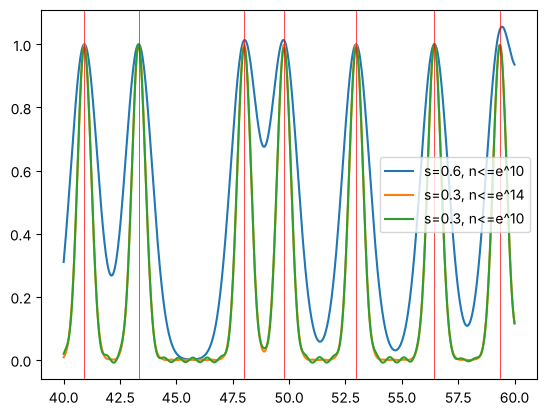

largest neglected term for s=0.3 beyond e^10: 0.00017916935824571631


In [18]:
NL2 = int(exp(14)); s2 = sieve(NL2); Lam2 = np.zeros(NL2 + 1)
for p in np.nonzero(s2)[0]:
    q = int(p)
    while q <= NL2: Lam2[q] = log(p); q *= int(p)
nz = np.nonzero(Lam2)[0]; lnz = np.log(nz); wz = Lam2[nz] / np.sqrt(nz)
def prime_side(T0, s, nmax):
    m = nz <= nmax
    return s / sqrt(2 * pi) * log(T0 / (2 * pi)) - 2 * s / sqrt(2 * pi) * np.sum(wz[m] * np.cos(T0 * lnz[m]) * np.exp(-s * s * lnz[m] ** 2 / 2))
Ts = np.linspace(40, 60, 600)
for s, nmax, lab in ((0.6, exp(10), "s=0.6, n<=e^10"), (0.3, exp(14), "s=0.3, n<=e^14"), (0.3, exp(10), "s=0.3, n<=e^10")):
    plt.plot(Ts, [prime_side(t, s, nmax) for t in Ts], label=lab)
for g0 in gam[(gam > 40) & (gam < 60)]: plt.axvline(g0, color="r", lw=0.5)
plt.legend(); plt.show()
print("largest neglected term for s=0.3 beyond e^10:", 2 * 0.3 / sqrt(2 * pi) * 10 * exp(-5) * exp(-0.045 * 100))

With $s=0.3$ and $n\le e^{14}$ the bumps are half as wide and every zero between $40$ and $60$ stands out, including the pair $48.01$, $49.77$, now well separated. With
$n\le e^{10}$ only, the curve is noisy: for $s=0.3$ the weight $e^{-s^2\log^2n/2}$ at $n=e^{10}$ is $e^{-4.5}\approx0.011$, not $e^{-18}$, so the neglected terms are of the same size as
the signal. Halving $s$ requires $\log n$ to double: the uncertainty principle of Journey 14.6(d).

### L14.2

In [19]:
P7 = P8[(P8 > 2) & (P8 <= 10 ** 7)]
d = np.cumsum(np.where(P7 % 4 == 3, 1, -1))
print("proportion of primes p <= 10^7 after which pi(x;4,3) > pi(x;4,1):", np.mean(d > 0), " ties:", np.mean(d == 0))
first = P7[np.argmax(d < 0)]; print("first p with pi(p;4,1) > pi(p;4,3):", first)

proportion of primes p <= 10^7 after which pi(x;4,3) > pi(x;4,1): 0.9994733500055675  ties: 0.000167023283948611
first p with pi(p;4,1) > pi(p;4,3): 26861


The race is led by the class $3\bmod4$ almost all the time (about $99.9\%$ of the primes up to $10^7$; the remainder are ties and a few short episodes), and the first time the
class $1$ leads is at $p=26\,861$, found by Leech in 1957. The reason is the same as in Journey 14.7: the explicit formula for $\psi(x;4,3)-\psi(x;4,1)$ has no bias, but converting
prime powers to primes removes the squares, and every odd square is $1\bmod4$, so $\pi(x;4,1)$ loses about $\frac12\pi(\sqrt x)$ relative to $\pi(x;4,3)$.

### L14.3

In [20]:
Pq = P8[(P8 > 2) & (P8 < 10 ** 5)]
best = []
for q in primerange(2, 2001):
    D = 1 - 4 * q
    roots = np.array([1 + chi(D, p) for p in Pq.tolist()], float)
    C2 = 2 * np.prod((1 - roots / Pq) / (1 - 1 / Pq))
    cnt = sum(1 for n in range(10 ** 4) if isprime(n * n + n + q))
    pred = C2 * sum(1 / log(n * n + n + q) for n in range(10 ** 4))
    best.append((C2, q, cnt, pred))
best.sort(reverse=True)
for C2, q, cnt, pred in best[:5]: print(q, round(C2, 3), cnt, round(pred, 1))
print("correlation of constant and count:", np.corrcoef([b[0] for b in best], [b[2] for b in best])[0, 1])

41 6.645 4149 4135.1
1997 5.696 3561 3530.1
1481 5.669 3556 3514.9
1019 5.316 3308 3297.9
941 5.27 3270 3269.7
correlation of constant and count: 0.9765037332420927


Among $q\le2000$, $q=41$ has the largest constant, about $6.64$, and also the most primes: the constant measures exactly the luck of avoiding small prime factors, which for
$n^2+n+q$ is maximal when $(\frac{1-4q}p)=-1$ for many small $p$, that is when the class number of $\mathbb Q(\sqrt{1-4q})$ is small. The counts follow the constants closely (the
correlation is about $0.98$), and for the top five the count is within about one per cent of the prediction.

### L14.4

In [21]:
def pq(h, k):
    out = []
    while h: out.append(k // h); h, k = k % h, h
    return out
k = 100003; diffs = []; alts = []
for h in range(1, k):
    a_ = pq(h, k); alt = sum(((-1) ** i) * t for i, t in enumerate(a_))
    diffs.append(12 * s_fast(h, k) - alt); alts.append(alt)
diffs = np.array(diffs); alts = np.array(alts)
print("max |12s - alt|:", np.abs(diffs).max(), " mean |alt|:", np.abs(alts).mean(), " log k =", log(k))

max |12s - alt|: 2.9999800006044097  mean |alt|: 69.94910101797964  log k = 11.512955464520237


The difference $12s(h,k)-(a_1-a_2+\cdots)$ stays below about $3$ in absolute value, while the alternating sums are often in the hundreds. Proof of (b): the recursion of
Journey 14.16(d) is $12s(h,k)=-12s(r_1,h)+\frac kh+\frac hk+\frac1{hk}-3$ with $\frac kh=a_1+\frac{r_1}h$, so each step contributes $a_1$ with alternating sign plus a term bounded by $2$ in
absolute value. With $n=O(\log k)$ steps, the difference is $O(\log k)$.